# Titanic: classify survival with a Random Forest

Original reference: [GeeksforGeeks: Random Forest](https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/).

Use passenger characteristics to predict survival and examine the errors made on a held-out test set.

### Topics
- Prepare categorical and missing values
- Choose features and split the data
- Train a Random Forest classifier
- Read a classification report and confusion matrix

**Question for the lesson:** Which survival outcomes does the model predict well, and where does it make mistakes?

> **Estimated time: 60 min**

## 1 · Import the tools

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 2 · Load and inspect passenger records

Read `titanic.csv` from the notebook folder. The target is `Survived`: `0` means did not survive and `1` means survived. Inspect the available columns before selecting inputs.

In [2]:
titanic_data = pd.read_csv('titanic.csv')
titanic_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 3 · Prepare the model inputs

Drop rows without a known survival label, encode `Sex` as `female = 0` and `male = 1`, and replace missing ages with the median.

In this introductory code, the age median is computed before the split, so it uses information from future test rows. For a stricter evaluation, split first, learn the median on training rows, and reuse it for test rows.

In [3]:
titanic_data = titanic_data.dropna(subset=['Survived'])
titanic_data['Sex'] = titanic_data['Sex'].map({'female': 0, 'male': 1})
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].median())

## 4 · Select features and split the data

Use passenger class (`Pclass`), encoded sex, age, siblings/spouses aboard (`SibSp`), parents/children aboard (`Parch`), and fare. Reserve 20% of rows for testing; `random_state=42` fixes the split.

In [4]:
X = titanic_data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]
y = titanic_data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5 · Train a Random Forest classifier

Fit 100 trees on the training data. Trees learn varied rules from bootstrap samples and random feature subsets; the classifier averages their class probabilities to choose a class.

In [5]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 6 · Predict one passenger

Keep the first test passenger as a one-row DataFrame so column names and feature order are preserved. The printed passenger details show the inputs used to predict survival.

In [6]:
sample = X_test.iloc[[0]]
prediction = rf_classifier.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"Sample Passenger: {sample_dict}")
print(f"Predicted Survival: {'Survived' if prediction[0] == 1 else 'Did Not Survive'}")

Sample Passenger: {'Pclass': 3.0, 'Sex': 1.0, 'Age': 28.0, 'SibSp': 1.0, 'Parch': 1.0, 'Fare': 15.2458}
Predicted Survival: Did Not Survive


In [7]:
jack = pd.DataFrame([{
	'Pclass': 3,
	'Sex': 1,
	'Age': 20,
	'SibSp': 0,
	'Parch': 0,
	'Fare': 10
}])
prediction = rf_classifier.predict(jack)
print(prediction)

[0]


In [8]:
rose = pd.DataFrame([{
	'Pclass': 1,
	'Sex': 0,
	'Age': 17,
	'SibSp': 0,
	'Parch': 1,
	'Fare': 50
}])
prediction = rf_classifier.predict(rose)
print(prediction)

[1]


## 7 · Evaluate the classifier

Accuracy is the fraction of correct test predictions. The classification report adds precision, recall, F1-score, and support for each class. Precision asks how often a predicted class is correct; recall asks how many actual members of that class were found. F1 balances precision and recall, while support counts actual examples.

In [9]:
y_pred = rf_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:")
print(classification_rep)

Accuracy: 0.7988826815642458
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



## 8 · Read the confusion matrix

Rows represent actual classes and columns represent predicted classes. Here, `Class 0` means did not survive and `Class 1` means survived. Correct predictions lie on the diagonal; the other cells show the two types of error.

### Pause & interpret

Which class has higher recall? Use the report and matrix together to explain which passengers the model most often misclassifies.

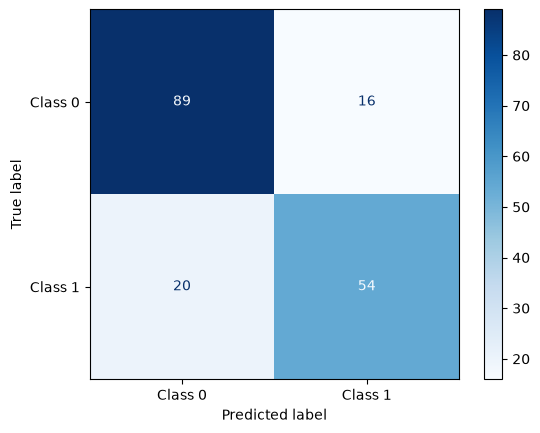

In [10]:
cm = confusion_matrix(y_test, y_pred)

# 2. Plot the matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

## Key takeaways

- Classification predicts discrete labels such as survived or did not survive.
- Encode categories and handle missing inputs before fitting a model.
- Fit learned preprocessing steps using training rows only.
- A confusion matrix and per-class metrics explain more than accuracy alone.